In [1]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models
import optimizers

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(device)

cuda


In [3]:
labels = pd.read_csv("../../labels/semi_cleaned_labels_3_features_2024-10-21.csv")
labels = labels.drop(columns=['MRN','SURGERY_DATE'])

new_labels = labels.replace('nan', np.nan)
new_labels = new_labels.replace('nc', np.nan)

# drop nans:
new_labels.dropna(inplace=True) # needs to happen before sorting into pre and post

new_labels_pre = new_labels[['ACC_NUM','LVEF_pre','RVSF_pre','TR_pre']]
new_labels_pre.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_pre['prepost'] = 0

new_labels_post = new_labels[['ACC_NUM','LVEF_post','RVSF_post','TR_post']]
new_labels_post.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_post['prepost'] = 1

new_labels = pd.concat([new_labels_pre, new_labels_post])
new_labels.reset_index(drop=True, inplace=True)

new_labels['LVEF'] = new_labels['LVEF'].astype(float)/100
new_labels['RVSF'] = new_labels['RVSF'].astype(float)/6
new_labels['TR'] = new_labels['TR'].astype(float)/7

ground_truths = pd.read_csv("../../labels/500_reports_groundtruth.csv")['ACC_NUM']

# drop nans:
new_labels.dropna(inplace=True)

ground_truths = list(ground_truths.astype(float))

training_labels = new_labels.drop(new_labels[new_labels['ACC_NUM'].isin(ground_truths)].index)
evaluation_labels = new_labels.drop(new_labels[~new_labels['ACC_NUM'].isin(ground_truths)].index) # not quite correct, but probably good enough until we clean the gt dataset

print(len(training_labels), len(evaluation_labels))

11120 842


/tmp/ipykernel_1888686/1912813610.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_pre['prepost'] = 0
/tmp/ipykernel_1888686/1912813610.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_post['prepost'] = 1


In [4]:
view_prediction_csvs = glob.glob("../../labels/view_predictions/cycle_*/predictions_all_cycle_*.csv", recursive=True)
predictions = []
for cycle_preds in view_prediction_csvs:
    cycle = pd.read_csv(cycle_preds)
    predictions.append(cycle.loc[cycle['prediction'] == 5]) # If filtering by view
    # predictions.append(cycle) # If not filtering by view

all_cycles = pd.concat(predictions)
all_cycles = all_cycles.reset_index()
val_cycles = all_cycles.sample(frac=0.025, random_state=0)
train_cycles = all_cycles.drop(val_cycles.index)

val_cycles = val_cycles.reset_index()
train_cycles = train_cycles.reset_index()

In [7]:
print(len(train_cycles))
removals = []
for i in tqdm.tqdm(range(len(train_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
train_cycles = train_cycles.drop(removals)
print(len(train_cycles))

print(len(val_cycles))
removals = []
for i in tqdm.tqdm(range(len(val_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
val_cycles = val_cycles.drop(removals)
print(len(val_cycles))
train_cycles = train_cycles.reset_index(drop=True)
val_cycles = val_cycles.reset_index(drop=True)

53187


100%|██████████| 53187/53187 [00:21<00:00, 2423.19it/s]


41738
1364


100%|██████████| 1364/1364 [00:00<00:00, 2393.99it/s]

1070


In [9]:
train_clips = list(train_cycles['clip_path'])
val_clips = list(val_cycles['clip_path'])

# train_clips = ['/data/deep_tee/' + clip[8:] for clip in train_clips]
# val_clips = ['/data/deep_tee/' + clip[8:] for clip in val_clips]

In [10]:
prepost_pred = pd.read_csv('/home/trevor/repos/deep_TEE/labels/preop_postop_prediction.csv')
acc_nums = [prepost_pred['clip_path'][i].split('/')[0] if type(prepost_pred['clip_path'][i])==str else '' for i in range(len(prepost_pred['clip_path']))]
dcm_nums = [prepost_pred['clip_path'][i].split('/')[-1] if type(prepost_pred['clip_path'][i])==str else ''  for i in range(len(prepost_pred['clip_path']))]
prepost_pred['ACC_NUM'] = acc_nums
prepost_pred['DCM_NUM'] = dcm_nums

In [11]:
train_transforms = datasets.TransformsComposed('train', size=(224,224))
valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))

features = ['LVEF','RVSF','TR']

train_dataset = datasets.VideoDataset(clip_paths=train_clips, labels_df=training_labels, features=features, time_df=prepost_pred, transform=train_transforms, duration=16, skip=2)
test_dataset = datasets.VideoDataset(clip_paths=val_clips, labels_df=training_labels,  features=features, time_df=prepost_pred, transform=valtest_transforms, duration=16, skip=2)

35009037


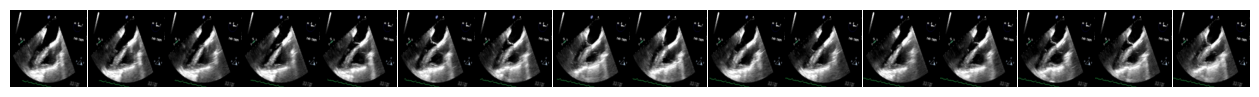

In [75]:
# Visualize the images
idx = np.random.randint(len(train_dataset))
parcel = train_dataset[idx]['data']
print(train_dataset[idx]['acc'])

# with torch.no_grad():
    # print(model(train_dataset[idx]['data'].unsqueeze(0).to(device)))
    # print(train_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
# plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))